In [1]:
!pip install -r requirements.txt

## 1. import dependancies

In [1]:
import pandas as pd #alias
import openai, groq 
import numpy as np #alias
from enum import Enum
from dotenv import load_dotenv
from pydantic import BaseModel # helps to create a class with a string type and a enum type, provdide the strucutre and extract the output 
import seaborn as sns
from dotenv import load_dotenv

load_dotenv()

False

In [2]:
%pip install openai

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install groq

  Using cached groq-1.7.0-py3-none-any.whl.metadata (16 kB)
Using cached groq-1.7.0-py3-none-any.whl (143 kB)
Note: you may need to restart the kernel to use updated packages.


## 2. Basic information

In [3]:
df = pd.read_csv('raw/Churn_modeling_ds_raw.csv')
df.head(15)

,RowNumber,CustomerId,Firstname,Lastname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Grace,Williams,619,France,Female,42.0,2,0.00,1,1,1,101348.88,1
1,2,15647311,David,Jones,608,Spain,Female,41.0,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Hank,Williams,502,France,Female,42.0,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Eva,Taylor,699,France,Female,NaN,1,0.00,2,0,0,93826.63,0
4,5,15737888,Grace,Miller,850,Spain,Female,43.0,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Jack,Smith,645,Spain,Male,44.0,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Carol,Wilson,822,France,Male,50.0,7,0.00,2,1,1,10062.80,0
7,8,15656148,Grace,Wilson,376,Germany,Female,29.0,4,115046.74,4,1,0,119346.88,1
8,9,15792365,Hank,Jones,501,France,Male,44.0,4,142051.07,2,0,1,74940.50,0
9,10,15592389,Eva,Wilson,684,France,Male,27.0,2,134603.88,1,1,1,71725.73,0


NaN = not a number

In [4]:
df.isnull().sum()

RowNumber            0
CustomerId           0
Firstname            7
Lastname             6
CreditScore          0
Geography            0
Gender             108
Age                600
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

## 3. Handle missing values

### 3.1 Deletion

axis = 1 -> check each column and drop if atleast 1 null value consits of

axis = 0 -> check each row and drop if atleast 1 null value consists of

In [5]:
df_copy = df.copy()
df_copy = df_copy.dropna(axis=1) 
df_copy.head(15)

# axis = 0 (check each row and drop if atleast 1 null value consits of)
# axis = 1 (check each column and drop if atleast 1 null value consits of)

# dropna(axis=1) = drop columns with atleast 1 null value
# dropna(axis=0) = drop rows with atleast 1 null value

# dropna(axis=1, how='all') = drop columns with all null values
# dropna(axis=0, how='all') = drop rows with all null values

# dropna(axis=1, how='any') = drop columns with any null values

,RowNumber,CustomerId,CreditScore,Geography,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,619,France,2,0.00,1,1,1,101348.88,1
1,2,15647311,608,Spain,1,83807.86,1,0,1,112542.58,0
2,3,15619304,502,France,8,159660.80,3,1,0,113931.57,1
3,4,15701354,699,France,1,0.00,2,0,0,93826.63,0
4,5,15737888,850,Spain,2,125510.82,1,1,1,79084.10,0
5,6,15574012,645,Spain,8,113755.78,2,1,0,149756.71,1
6,7,15592531,822,France,7,0.00,2,1,1,10062.80,0
7,8,15656148,376,Germany,4,115046.74,4,1,0,119346.88,1
8,9,15792365,501,France,4,142051.07,2,0,1,74940.50,0
9,10,15592389,684,France,2,134603.88,1,1,1,71725.73,0


In [6]:
10000 - 9337

663

In [7]:
df_copy = df.copy()
df_copy = df_copy.dropna(axis=1) 
df_copy

,RowNumber,CustomerId,CreditScore,Geography,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,619,France,2,0.00,1,1,1,101348.88,1
1,2,15647311,608,Spain,1,83807.86,1,0,1,112542.58,0
2,3,15619304,502,France,8,159660.80,3,1,0,113931.57,1
3,4,15701354,699,France,1,0.00,2,0,0,93826.63,0
4,5,15737888,850,Spain,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,771,France,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,516,France,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,709,France,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,772,Germany,3,75075.31,2,1,0,92888.52,1


### 3.2 Imputation

The possible ways to do this are:

- Filling the missing data with the mean or median value if its a numerical variable.
- Filling the missing data with mode if its a categorical value
- Filling the numerical value with 0 or -999, or some other number that will not occur in the data. This can be done so that the machine can recognize that the data is not real or is different.
- Filling the categorical value with a new type for the missing value. 

### 3.2.1 Age

In [8]:
mean = df['Age'].mean()
median = df['Age'].median()
mean = round(mean, 2)

print(f"Mean | Age: {mean}")
print(f"Median | Age: {median}")

Mean | Age: 38.91
Median | Age: 37.0


<Axes: xlabel='Age', ylabel='Count'>

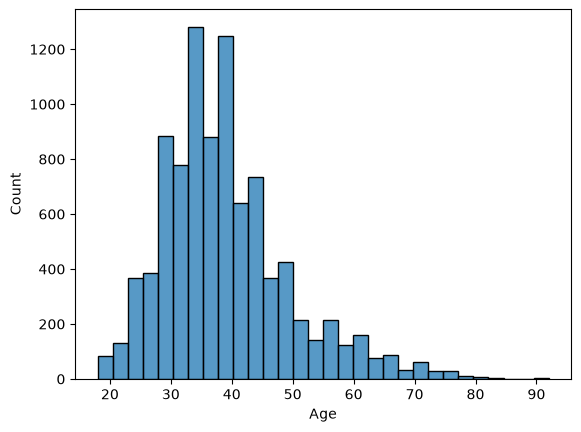

In [9]:
sns.histplot(df['Age'], bins=30)

In [10]:
df_impute = df.copy()

In [11]:
df_impute.loc[:, 'Age'] = df_impute['Age'].fillna(mean)
df_impute

,RowNumber,CustomerId,Firstname,Lastname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Grace,Williams,619,France,Female,42.00,2,0.00,1,1,1,101348.88,1
1,2,15647311,David,Jones,608,Spain,Female,41.00,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Hank,Williams,502,France,Female,42.00,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Eva,Taylor,699,France,Female,38.91,1,0.00,2,0,0,93826.63,0
4,5,15737888,Grace,Miller,850,Spain,Female,43.00,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Grace,Garcia,771,France,Male,39.00,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Jack,Garcia,516,France,Male,35.00,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Carol,Johnson,709,France,Female,36.00,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Jack,Garcia,772,Germany,Male,42.00,3,75075.31,2,1,0,92888.52,1


In [12]:
df_impute.isnull().sum()

RowNumber            0
CustomerId           0
Firstname            7
Lastname             6
CreditScore          0
Geography            0
Gender             108
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

### 3.2.2 Gender

In [27]:
class Gender(str, Enum):
    MALE = 'Male'
    FEMALE = 'Female'

class GenderPrediction(BaseModel):   #structuerd outputs from an LLM
    firstname: str
    lastname: str
    pred_gender: Gender

def predict_gender(
        firstname: str,
        lastname: str
        ):
    
    prompt = f"""
                what is the most likely gender (male or female) for someone with the first name '{firstname}' 
                and the last name '{lastname}' ?

                your resposne only consists of one word: male or female

                """
    
    response = groq.Groq().chat.completions.create(
                                                    model="openai/gpt-oss-120b",
                                                    messages=[{
                                                            "role" : "user",
                                                            "content" : prompt
                                                    }]
                                                )
    
    predicted_gender = response.choices[0].message.content.strip().capitalize()

    if predicted_gender not in ["Male", "Female"]:
        return None
        
    
    prediction = GenderPrediction(
                                firstname=firstname ,
                                lastname=lastname,
                                pred_gender=predicted_gender
                                )
    return prediction.pred_gender

In [28]:
import os
from getpass import getpass

os.environ["GROQ_API_KEY"] = getpass("Enter your Groq API key: ")

Enter your Groq API key:  ········


In [29]:
predict_gender("John", "Doe")



<Gender.MALE: 'Male'>

In [30]:
df_impute.isnull().sum()

RowNumber            0
CustomerId           0
Firstname            7
Lastname             6
CreditScore          0
Geography            0
Gender             107
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

In [31]:
missing_gender_index = df_impute['Gender'].isnull()
for idx in df_impute[missing_gender_index].index:
    first_name = df_impute.loc[idx, 'Firstname']
    last_name = df_impute.loc[idx, 'Lastname']
    gender = predict_gender(first_name, last_name)
    
    if gender:
        df_impute.loc[idx, 'Gender'] = gender
        print(f"{first_name} {last_name} : {gender}")
    else:
        print(f"{first_name} {last_name} : No Gender Detected")

Ivy Johnson : Gender.FEMALE
David Taylor : Gender.MALE
Frank Davis : Gender.MALE
Jack Wilson : No Gender Detected
David Miller : Gender.MALE
Eva Taylor : Gender.FEMALE
Grace Johnson : No Gender Detected
Hank Miller : Gender.MALE
Frank Williams : Gender.MALE
Alice Davis : Gender.FEMALE
Alice Brown : Gender.FEMALE
Alice Garcia : Gender.FEMALE
Bob Jones : No Gender Detected
Jack Davis : Gender.MALE
Grace Williams : No Gender Detected
Ivy Jones : No Gender Detected
David Smith : Gender.MALE
David Miller : No Gender Detected
Eva Williams : Gender.FEMALE
Frank Garcia : No Gender Detected
Alice Wilson : Gender.FEMALE
Carol Jones : Gender.FEMALE
Hank Davis : No Gender Detected
Ivy Williams : Gender.FEMALE
Hank Smith : Gender.MALE
Ivy Jones : Gender.FEMALE
Alice Brown : Gender.FEMALE
Eva Taylor : Gender.FEMALE
Carol Williams : No Gender Detected
Jack Williams : Gender.MALE
Ivy Brown : No Gender Detected
David Brown : Gender.MALE
Bob Smith : Gender.MALE
Frank Wilson : Gender.MALE
Bob Williams : 

In [25]:
df_impute.isnull().sum()

RowNumber            0
CustomerId           0
Firstname            7
Lastname             6
CreditScore          0
Geography            0
Gender             107
Age                  0
Tenure               0
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

In [32]:
df_impute.head()

,RowNumber,CustomerId,Firstname,Lastname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Grace,Williams,619,France,Female,42.00,2,0.00,1,1,1,101348.88,1
1,2,15647311,David,Jones,608,Spain,Female,41.00,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Hank,Williams,502,France,Female,42.00,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Eva,Taylor,699,France,Female,38.91,1,0.00,2,0,0,93826.63,0
4,5,15737888,Grace,Miller,850,Spain,Female,43.00,2,125510.82,1,1,1,79084.10,0


In [33]:
df_impute.isnull().sum()

RowNumber           0
CustomerId          0
Firstname           7
Lastname            6
CreditScore         0
Geography           0
Gender             25
Age                 0
Tenure              0
Balance             0
NumOfProducts       0
HasCrCard           0
IsActiveMember      0
EstimatedSalary     0
Exited              0
dtype: int64

In [34]:
df_impute.to_csv('processed/ChurnModelling_Missing_values_handled.csv',
                 index=False)